# Currents and voltages
Contact current transients, impact ionization, I-V and spectra.
Figures are saved in `SAVE_DIR` as `.png`, `.pdf` and editable `.mplfig`
(reopen with `python open_fig.py <file>.mplfig` or `mcplot.load_figure`).
Plotting functions are in `transient_plots.py`.

In [1]:
# Interactive figures (zoom/pan) need ipympl; otherwise fall back to static figures
try:
    import ipympl  # noqa: F401
    get_ipython().run_line_magic("matplotlib", "widget")
except ImportError:
    get_ipython().run_line_magic("matplotlib", "inline")
import os

import matplotlib.pyplot as plt
import numpy as np
import transient_plots as tp
from mcplot import save_figure, set_style

set_style(25)

SAVE_FIGURES = True  # save every figure as .png, .pdf and editable .mplfig
SAVE_DIR = "output/currents_and_voltages"


def save(fig, name):
    """Save fig as SAVE_DIR/name.{png,pdf,mplfig} (reopen the .mplfig with open_fig.py)."""
    if SAVE_FIGURES:
        save_figure(fig, os.path.join(SAVE_DIR, name), formats=("png", "pdf"), dpi=300, bbox_inches="tight")

# Current and voltage
SPAD current, quenching voltage $V_q$ and SPAD voltage drop $V_d = V_{bias} - V_q$.

In [23]:
base_path = "/home/angelo/server/csmhome2/amudano/Projects/MC3D/DEMC/SPAD_FBK_v2/quasi_1D"
folder_list = ["CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_1e-16","CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_1e-16_2","CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_1e-17","CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_1e-172"]
# folder_list = ["CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_inj_on_top","CONTINUE/deep_implant_1.0/1SC/quenching--37.00V","CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_1e-16","CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_1e-17"]
label_list = ["1e-16 1","1e-16 2","1e-17 1","1e-17 2"]

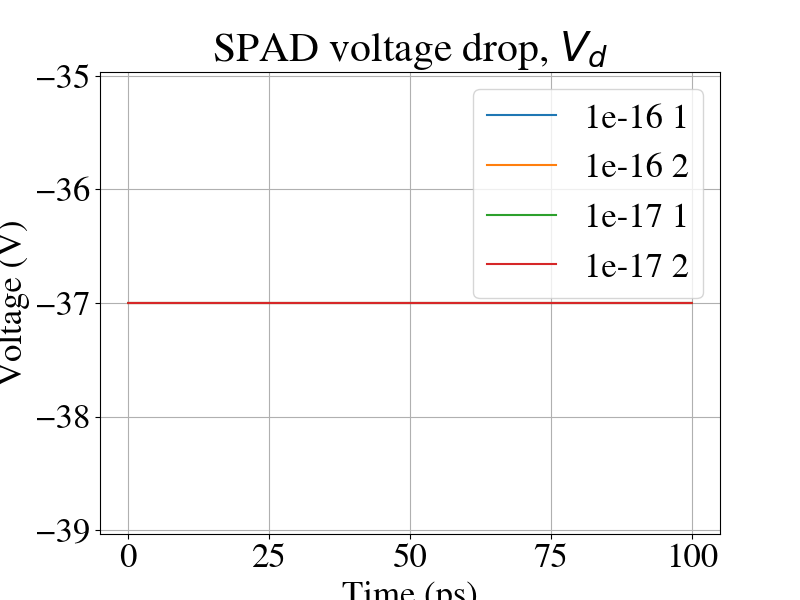

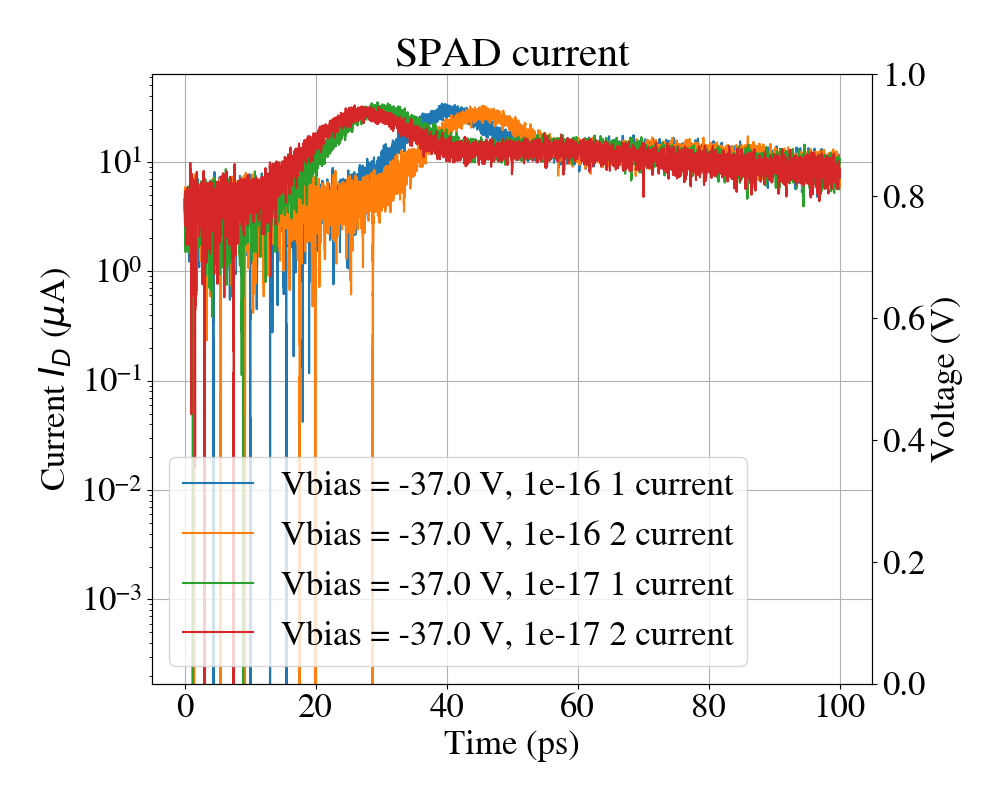

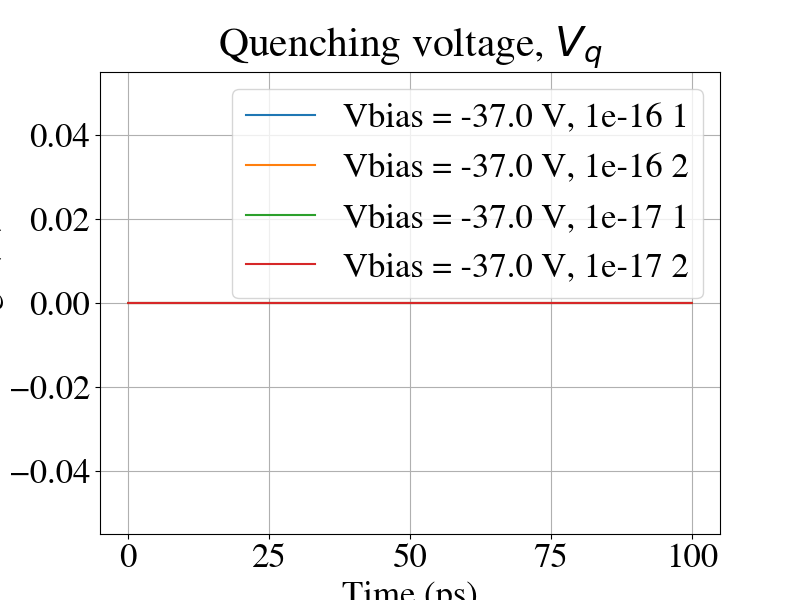

In [24]:
plt.close("all")
fig_i, fig_vq, fig_vd = tp.current_and_voltage_figures(base_path, folder_list, label_list, contact="ncontact",
                                                       voltage_on_twin=False)
save(fig_i, "spad_current")
save(fig_vq, "quenching_voltage")
save(fig_vd, "voltage_drop")
plt.show()


## Growth rate: Continue vs FF
Savitzky-Golay filtered currents of the folders above, baseline subtracted (Continue has ~3 µA), compared on the rising edge in a time window and a current window.

In [2]:
base_path = "/home/angelo/server/csmhome2/amudano/Projects/MC3D/DEMC/SPAD_FBK_v2/quasi_1D"
folder_list = ["CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_1e-16","FF/deep_implant_1.0/breakdown--37.00V-s2"]
label_list = ["SC","FF"]

SC: baseline 3.84 µA, 10020 points in [26.42, 34.47] ps -> growth rate 0.2686 1/ps, tau = 3.723 ps
FF: baseline 0 µA, 9623 points in [21.35, 29.05] ps -> growth rate 0.2498 1/ps, tau = 4.004 ps


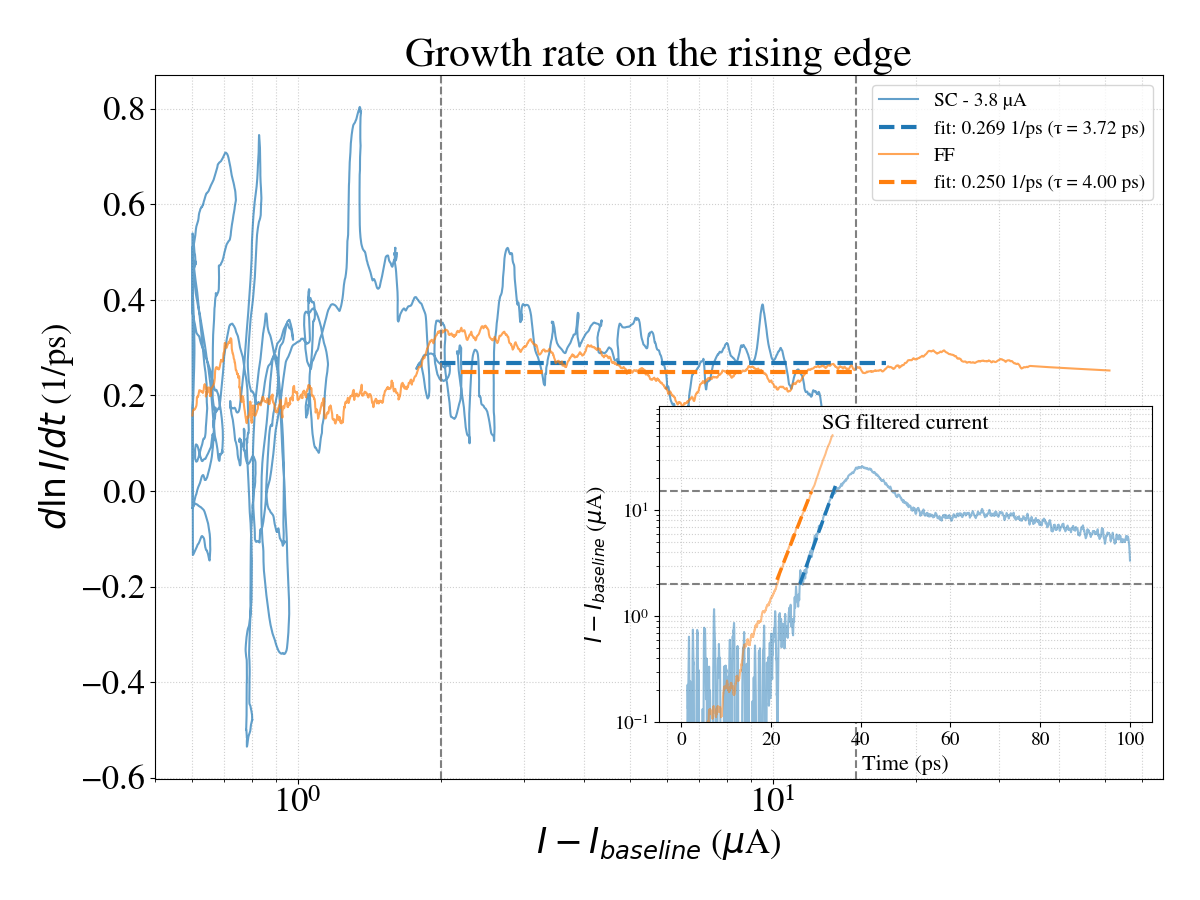

In [3]:
plt.close("all")
from scipy.signal import savgol_filter

# Growth-rate comparison. Each current is Savitzky-Golay filtered, its baseline is subtracted and
# ln(I) is fitted with a line on the rising edge (up to the peak) where t is in the curve's time
# window and I - baseline is in I_win. Keys of the dicts = labels in label_list; labels not in
# the dicts use baseline None and t_win_default.
baseline = {"SC": None, "FF": 0.0}  # A; None: mean of the current for t < t_base
t_base = 5.0  # ps
t_win = {"SC": (5.0, 100.0), "FF": (5.0, 100.0)}  # ps
t_win_default = (0.0, np.inf)  # ps
I_win = (2e-6, 15e-6)  # A, on the baseline-subtracted current
sg_window = 1.0  # ps, filter of the current (converted to an odd number of samples)
sg_window_rate = 3.0  # ps, filter used for the instantaneous growth rate d(ln I)/dt
sg_order = 3
inset_bounds = (0.5, 0.08, 0.49, 0.45)  # filtered current inset: x0, y0, width, height (axes fraction)


def sg_samples(window_ps, dt):
    return max(int(round(window_ps / dt)) | 1, sg_order + 2)


fig, ax_r = plt.subplots(figsize=(12, 9))
ax_i = ax_r.inset_axes(inset_bounds)
for (folder, lab), color in zip(zip(folder_list, label_list), plt.cm.tab10.colors):
    r = tp.read_transient(base_path, folder, contact="ncontact")
    t = r.t * 1e12  # ps
    dt = np.median(np.diff(t))
    I_bg = baseline.get(lab)
    if I_bg is None:
        I_bg = r.current[t < t_base].mean()
    I = savgol_filter(r.current, sg_samples(sg_window, dt), sg_order) - I_bg
    w_rate = sg_samples(sg_window_rate, dt)
    I_rate = savgol_filter(r.current, w_rate, sg_order) - I_bg
    rate = savgol_filter(r.current, w_rate, sg_order, deriv=1, delta=dt) / I_rate  # 1/ps

    t0, t1 = t_win.get(lab, t_win_default)
    in_t = (t >= t0) & (t <= t1)
    rising = in_t & (np.arange(len(t)) <= np.argmax(np.where(in_t, I, -np.inf)))
    fit = rising & (I >= I_win[0]) & (I <= I_win[1])

    lab_bg = f"{lab} - {I_bg * 1e6:.2g} µA" if I_bg else lab
    ax_i.semilogy(t, np.where(I > 0, I, np.nan) * 1e6, color=color, alpha=0.5)
    show_rate = rising & (I_rate > 0.3 * I_win[0])
    ax_r.semilogx(I_rate[show_rate] * 1e6, rate[show_rate], color=color, alpha=0.7, label=lab_bg)
    if fit.sum() < 2:
        print(f"{lab}: fewer than 2 points in the window, no fit")
        continue
    slope, intercept = np.polyfit(t[fit], np.log(I[fit]), 1)
    t_fit = t[fit][[0, -1]]
    ax_i.semilogy(t_fit, np.exp(slope * t_fit + intercept) * 1e6, "--", color=color, linewidth=2.5)
    ax_r.hlines(slope, *(np.exp(slope * t_fit + intercept) * 1e6), color=color, linestyle="--", linewidth=3,
                label=f"fit: {slope:.3f} 1/ps (τ = {1 / slope:.2f} ps)")
    print(f"{lab}: baseline {I_bg * 1e6:.3g} µA, {fit.sum()} points in [{t_fit[0]:.2f}, {t_fit[1]:.2f}] ps "
          f"-> growth rate {slope:.4f} 1/ps, tau = {1 / slope:.3f} ps")

for I_lim in I_win:  # current window: grey dashed lines
    ax_r.axvline(I_lim * 1e6, color="grey", linestyle="--", linewidth=1.5)
    ax_i.axhline(I_lim * 1e6, color="grey", linestyle="--", linewidth=1.5)
ax_i.set_xlabel("Time (ps)", fontsize=16)
ax_i.set_ylabel(r"$I - I_{baseline}$ ($\mu$A)", fontsize=16)
ax_i.set_title("SG filtered current", fontsize=16,y=0.9)
ax_i.tick_params(labelsize=14)
ax_i.set_ylim(bottom=0.05 * I_win[0] * 1e6)  # hide the noise of the baseline-subtracted current
ax_i.grid(True, which="both", linestyle=":", alpha=0.6)
ax_r.set_xlabel(r"$I - I_{baseline}$ ($\mu$A)")
ax_r.set_ylabel(r"$d\ln I/dt$ (1/ps)")
ax_r.set_title("Growth rate on the rising edge")
ax_r.grid(True, which="both", linestyle=":", alpha=0.6)
ax_r.set_xlim(0.5e0,)
ax_r.legend(fontsize=14, loc="upper right")
fig.tight_layout()
save(fig, "growth_rate_comparison")
plt.show()

# Impact ionization
## Current and impact ionization events

In [4]:
base_path = "/home/angelo/mnt/server/MonteCarlo/DEMC/SPAD_FBK_v2/3D"
folder_list = ["4um/CONTINUE/1SC/quenching--37.00V_3ns"]
# folder_list = ["4um/CONTINUE/1SC/quenching--37.00V_1ns_R100k_C5f", "4um/CONTINUE/1SC/quenching--37.00V_1ns_R150k_C5f"]
label_list = ["32", "37"]

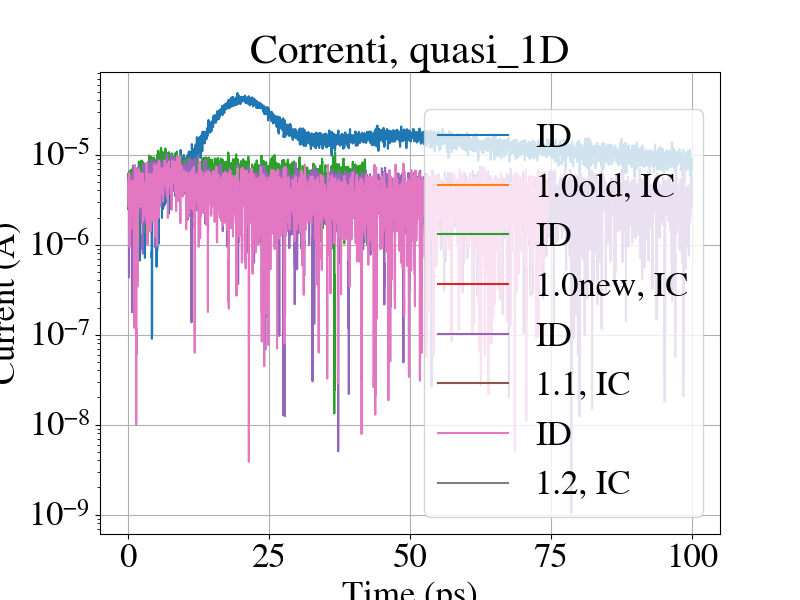

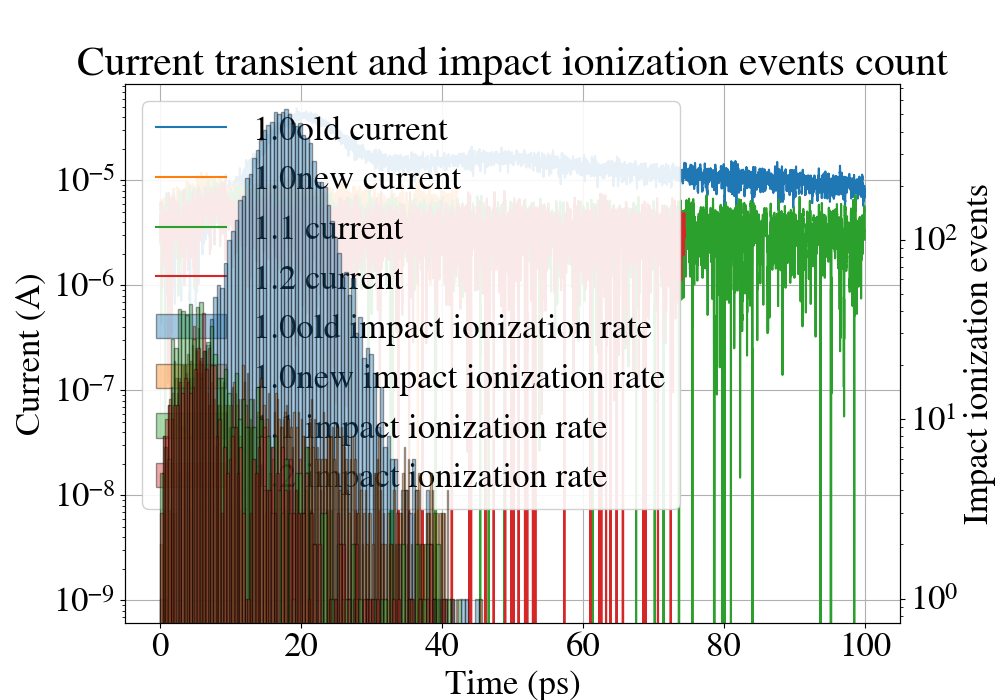

In [118]:
plt.close("all")
fig = tp.current_and_ionization_figure(base_path, folder_list, label_list, contact="ncontact", figsize=(10, 7))
save(fig, "current_and_ionization")
fig = tp.diode_and_capacitive_current_figure(base_path, folder_list, label_list, contact="ncontact",
                                             legend_loc="lower right")
save(fig, "diode_and_capacitive_current")
plt.show()

## Impact ionization events

In [ ]:
base_path = "/home/angelo/mnt/server/MonteCarlo/DEMC/SPAD_FBK_v2/quasi_1D"
folder_list = ["FF/deep_implant_1.0/breakdown--40.00V-s999"]
# bias = [-37]
# folder_list = [f"MC/new_mesh/voltage_ramp-1fs-{v:.2f}V" for v in bias]
label_list = ["continue", "no full contact"]
t_stop = 150e-12  # histogram range: [0, t_stop]

In [ ]:
plt.close("all")
fig = tp.ionization_events_figure(base_path, folder_list, label_list, t_stop, figsize=(15, 7))
save(fig, "ionization_events")
plt.show()

# I-V characteristic
Mean of the last 10 current samples of every voltage-ramp simulation.

In [ ]:
set_style(15)
base_path = "/mnt/polmcad/MonteCarlo/DEMC/SPAD_FBK_v2/3D/MC"
bias = np.linspace(-35, -15, 21)

In [ ]:
plt.close("all")
fig = tp.iv_figure(base_path, bias, folder_fmt="voltage_ramp-{v:.2f}V", contact="pcontact")
save(fig, "iv_characteristic")
plt.show()

# Current transient

In [ ]:
base_path = "/home/angelo/mnt/server/MonteCarlo/DEMC/SPAD_FBK_v2/no_epi"
folder_list = ["FF/3D/avalanche_m37", "FF/3D/avalanche_m32"]
# bias = np.linspace(-30, -40, 11)
# folder_list = [f"MC/equal_doping/voltage_ramp-{v:.2f}V" for v in bias]
label_list = ["37", "32", "active bulk"]

In [ ]:
plt.close("all")
fig = tp.current_transient_figure(base_path, folder_list, label_list, contact="ncontact", figsize=(10, 7),
                                  log=True, legend_loc="upper right")
save(fig, "current_transient")
plt.show()

## Savitzky-Golay filtered current

In [ ]:
window_length = 101  # must be odd
polyorder = 3

In [ ]:
plt.close("all")
fig = tp.current_transient_figure(base_path, folder_list, label_list, contact="pcontact", figsize=(8, 6),
                                  log=False, legend_loc="lower left", sv_filter=(window_length, polyorder))
save(fig, "current_transient_sv_filter")
plt.show()

## Current spectrum (FFT)
Uses the folders of the *Current transient* section. Valid only for constant dt.

In [ ]:
plt.close("all")
fig = tp.current_fft_figure(base_path, folder_list, label_list, contact="p-contact")
save(fig, "current_fft")
plt.show()

# Scattering rate

In [ ]:
path = "/mnt/polmcad/MonteCarlo/Materials/silicon_mio/scattering/Energy_Rates"
scattering_file = f"{path}/e_acoabs_TA_band_5_band_5.txt"

In [ ]:
plt.close("all")
fig = tp.scattering_rate_figure(scattering_file, xlim=(0, 4))
save(fig, "scattering_rate")
plt.show()